In [23]:

import seaborn as sns

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")


In [24]:
import seaborn as sns

In [25]:
# Load the 'taxis' dataset

In [26]:
df = sns.load_dataset("taxis")

In [27]:

print(df.head())
print(df.shape)
print(df.columns)


               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [28]:

# Check missing values in each column
print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [30]:

# Show columns that contain missing values
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])


payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [32]:

# Remove rows where important values are missing
df = df.dropna(subset=["pickup", "fare"])

# Fill missing values in each column
for column in df.columns:
    if df[column].isnull().any():

        # Numerical columns
        if df[column].dtype.kind in "iuf":
            df[column] = df[column].fillna(
                df[column].median()
            )

        # Categorical columns
        else:
            mode_values = df[column].mode()

            if not mode_values.empty:
                df[column] = df[column].fillna(
                    mode_values[0]
                )

# Check missing values
print(df.isnull().sum())



pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [33]:
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

Dataset shape: (6433, 14)
Total missing values: 0


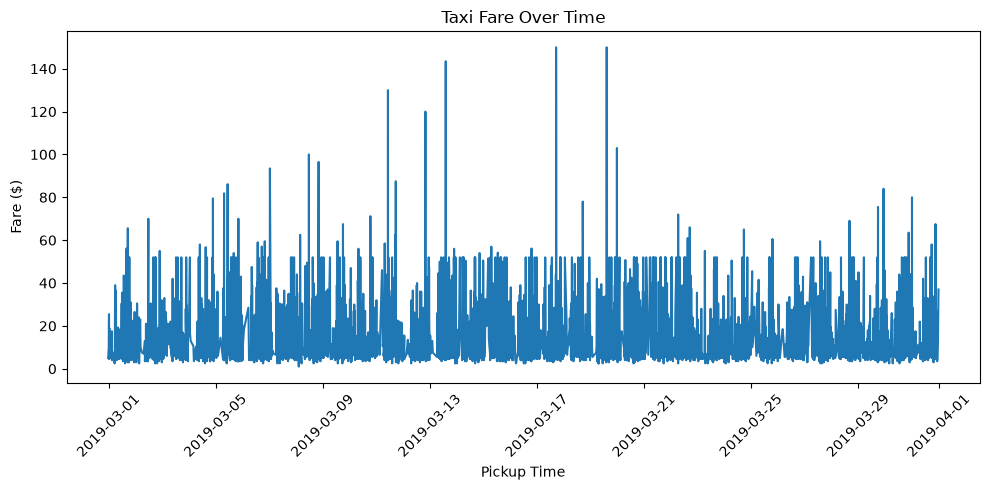

In [34]:

import matplotlib.pyplot as plt
import pandas as pd

# Convert pickup column to datetime format
df["pickup"] = pd.to_datetime(df["pickup"])

# Sort data by pickup time
df = df.sort_values("pickup")

# Create line chart
plt.figure(figsize=(10, 5))
plt.plot(df["pickup"], df["fare"])

# Add title and labels
plt.title("Taxi Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare ($)")

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [35]:
df["pickup"] = pd.to_datetime(df["pickup"])


In [36]:
df = df.sort_values("pickup")

In [37]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

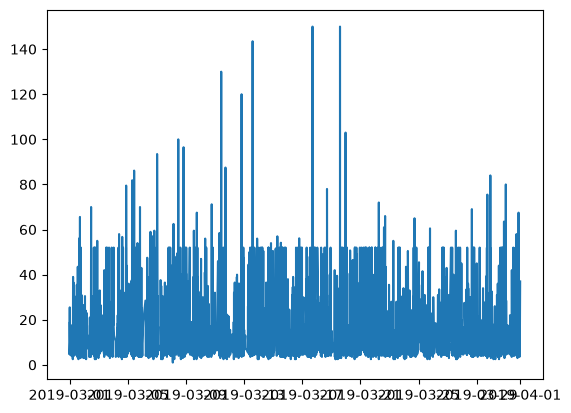

In [38]:
plt.plot(df["pickup"], df["fare"])

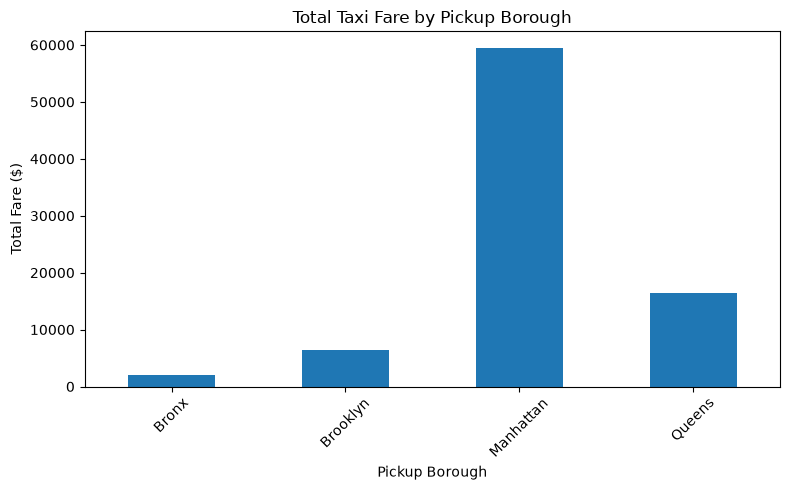

In [39]:

import matplotlib.pyplot as plt

# Calculate total fare for each pickup borough
borough_fare = df.groupby("pickup_borough")["fare"].sum()

# Create bar chart
borough_fare.plot(kind="bar", figsize=(8, 5))

# Add title and labels
plt.title("Total Taxi Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")

# Improve readability
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [42]:
import matplotlib.pyplot as plt

In [43]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()

<Axes: xlabel='pickup_borough'>

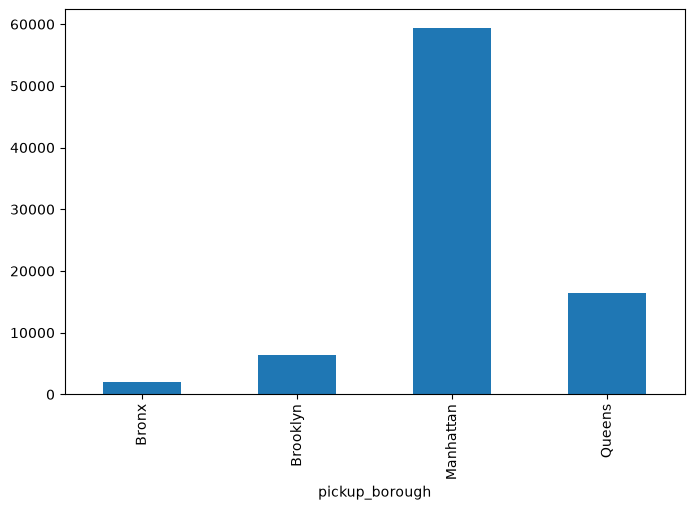

In [44]:
borough_fare.plot(kind="bar", figsize=(8, 5))

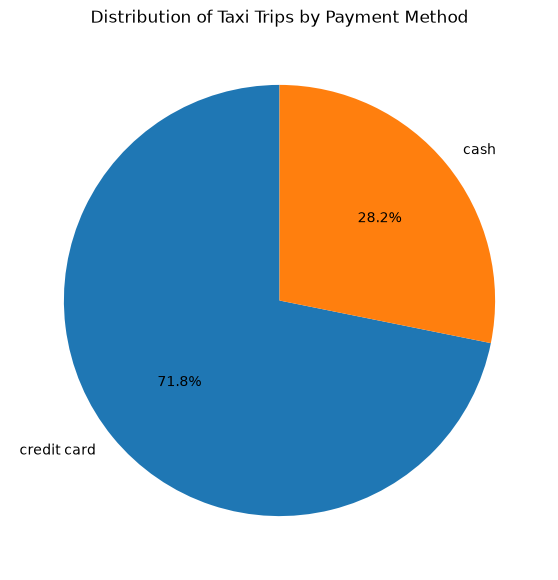

In [46]:

import matplotlib.pyplot as plt

# Count trips for each payment method
payment_counts = df["payment"].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

# Add title
plt.title("Distribution of Taxi Trips by Payment Method")

# Display chart
plt.show()


In [47]:
import matplotlib.pyplot as plt


In [48]:
payment_counts = df["payment"].value_counts()

In [49]:
plt.figure(figsize=(7, 7))

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

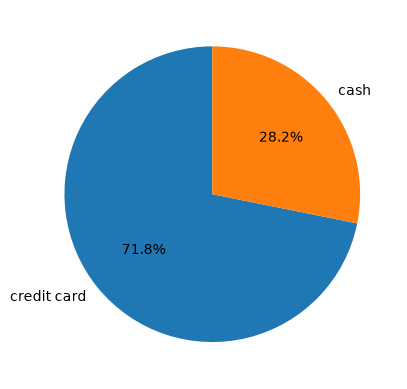

In [50]:
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

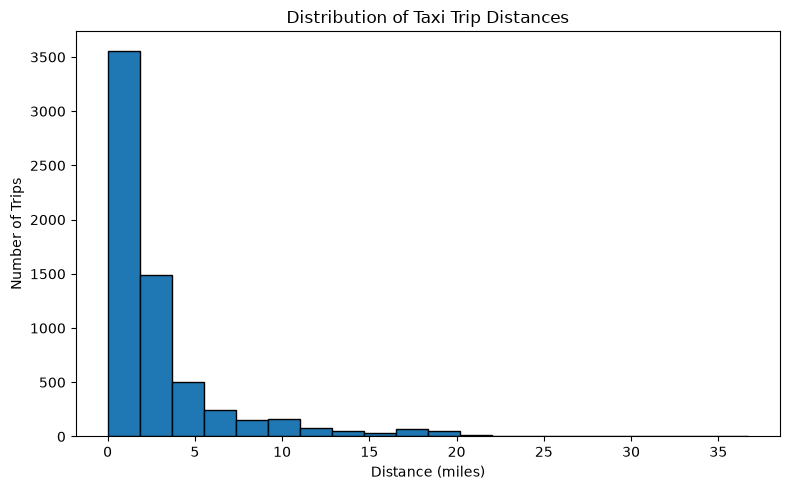

In [51]:

import matplotlib.pyplot as plt

# Create a histogram of taxi trip distances
plt.figure(figsize=(8, 5))
plt.hist(df["distance"].dropna(), bins=20, edgecolor="black")

# Add title and labels
plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")

# Display the chart
plt.tight_layout()
plt.show()


In [52]:
import matplotlib.pyplot as plt

In [54]:
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

(array([3.559e+03, 1.491e+03, 5.010e+02, 2.450e+02, 1.560e+02, 1.630e+02,
        7.500e+01, 5.100e+01, 3.600e+01, 6.700e+01, 5.000e+01, 1.500e+01,
        9.000e+00, 6.000e+00, 2.000e+00, 2.000e+00, 1.000e+00, 0.000e+00,
        2.000e+00, 2.000e+00]),
 array([ 0.   ,  1.835,  3.67 ,  5.505,  7.34 ,  9.175, 11.01 , 12.845,
        14.68 , 16.515, 18.35 , 20.185, 22.02 , 23.855, 25.69 , 27.525,
        29.36 , 31.195, 33.03 , 34.865, 36.7  ]),
 <BarContainer object of 20 artists>)

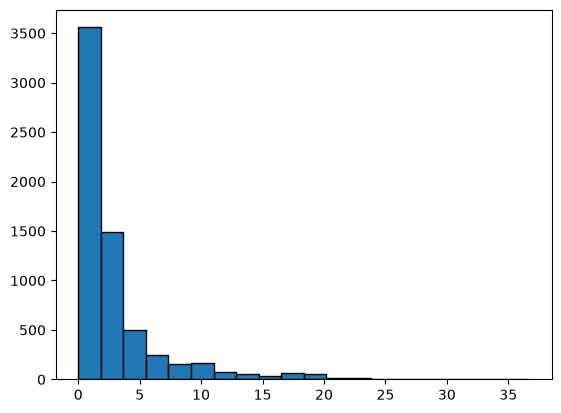

In [55]:
plt.hist(df["distance"].dropna(), bins=20, edgecolor="black")

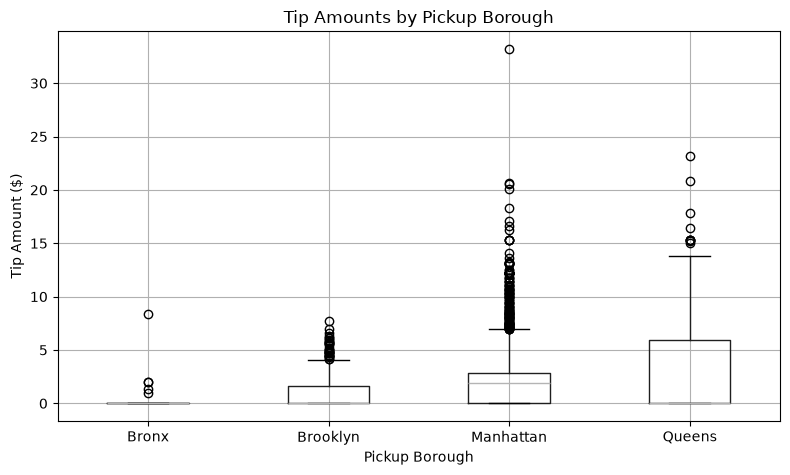

In [56]:

import matplotlib.pyplot as plt

# Remove rows with missing borough or tip values
box_data = df.dropna(subset=["pickup_borough", "tip"])

# Create box plot
box_data.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(8, 5)
)

# Add title and labels
plt.title("Tip Amounts by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")

# Display chart
plt.tight_layout()
plt.show()


In [57]:
import matplotlib.pyplot as plt

In [58]:
box_data = df.dropna(subset=["pickup_borough", "tip"])

<Axes: title={'center': 'tip'}, xlabel='pickup_borough'>

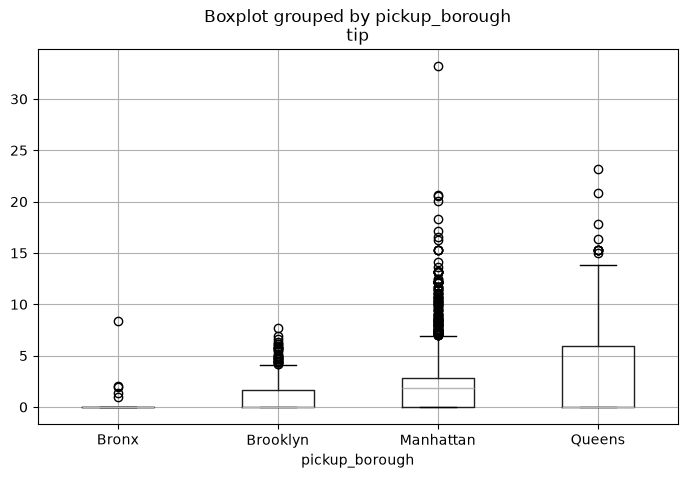

In [59]:
box_data.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(8, 5)
)

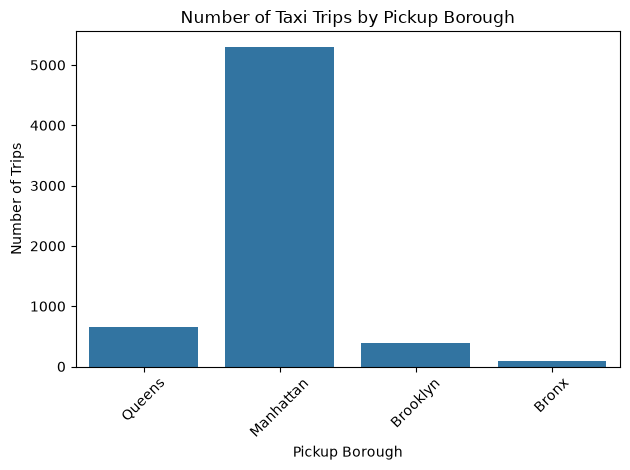

In [60]:

import seaborn as sns
import matplotlib.pyplot as plt

# Create count plot
sns.countplot(data=df, x="pickup_borough")

# Add title and labels
plt.title("Number of Taxi Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")

# Display chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [61]:
import seaborn as sns

In [62]:
import matplotlib.pyplot as plt

<Axes: xlabel='pickup_borough', ylabel='count'>

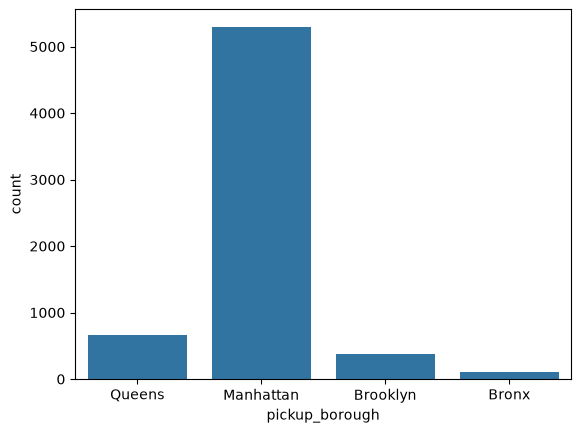

In [63]:
sns.countplot(data=df, x="pickup_borough")

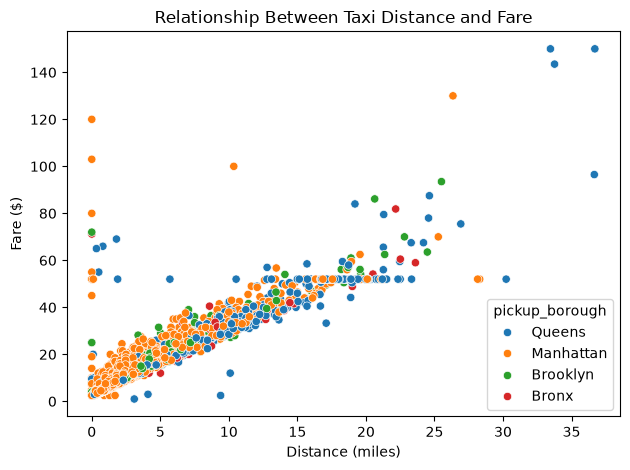

In [65]:

import seaborn as sns
import matplotlib.pyplot as plt

# Create scatter plot
sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

# Add title and labels
plt.title("Relationship Between Taxi Distance and Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")

# Display chart
plt.tight_layout()
plt.show()


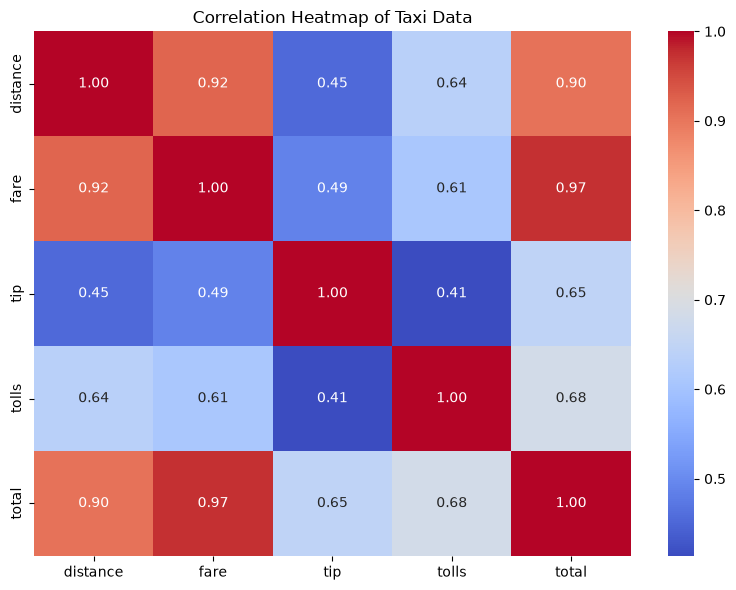

In [66]:

import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numeric_data = df[["distance", "fare", "tip", "tolls", "total"]]

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Add title
plt.title("Correlation Heatmap of Taxi Data")

# Display chart
plt.tight_layout()
plt.show()


In [67]:
numeric_data = df[["distance", "fare", "tip", "tolls", "total"]]

In [68]:
correlation_matrix = numeric_data.corr()

<Axes: >

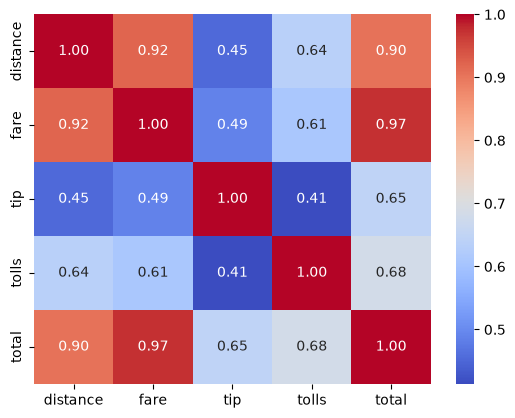

In [69]:
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

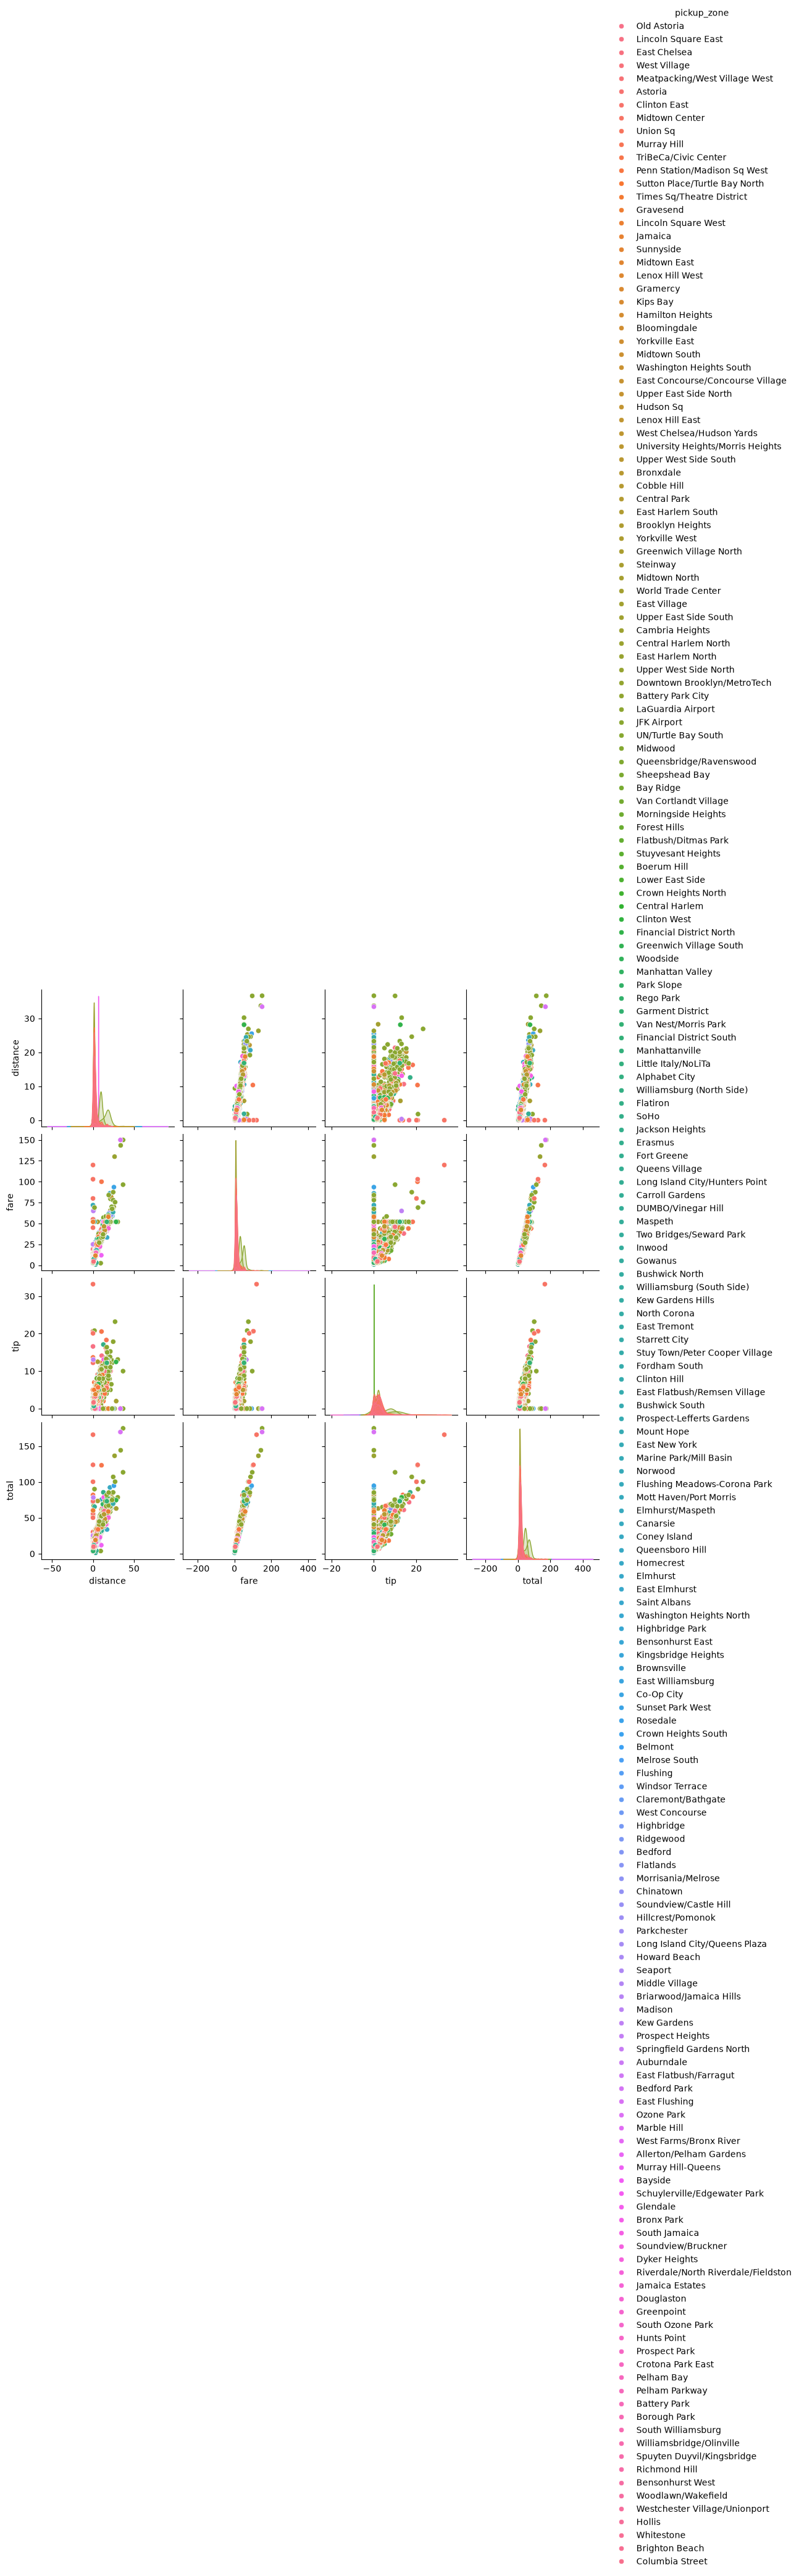

In [70]:

import seaborn as sns
import matplotlib.pyplot as plt

# Select columns for the pair plot
pair_data = df[["distance", "fare", "tip", "total", "pickup_zone"]].dropna()

# Create pair plot
sns.pairplot(
    pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone"
)

# Display chart
plt.show()


In [72]:
pair_data = df[["distance", "fare", "tip", "total", "pickup_zone"]].dropna()

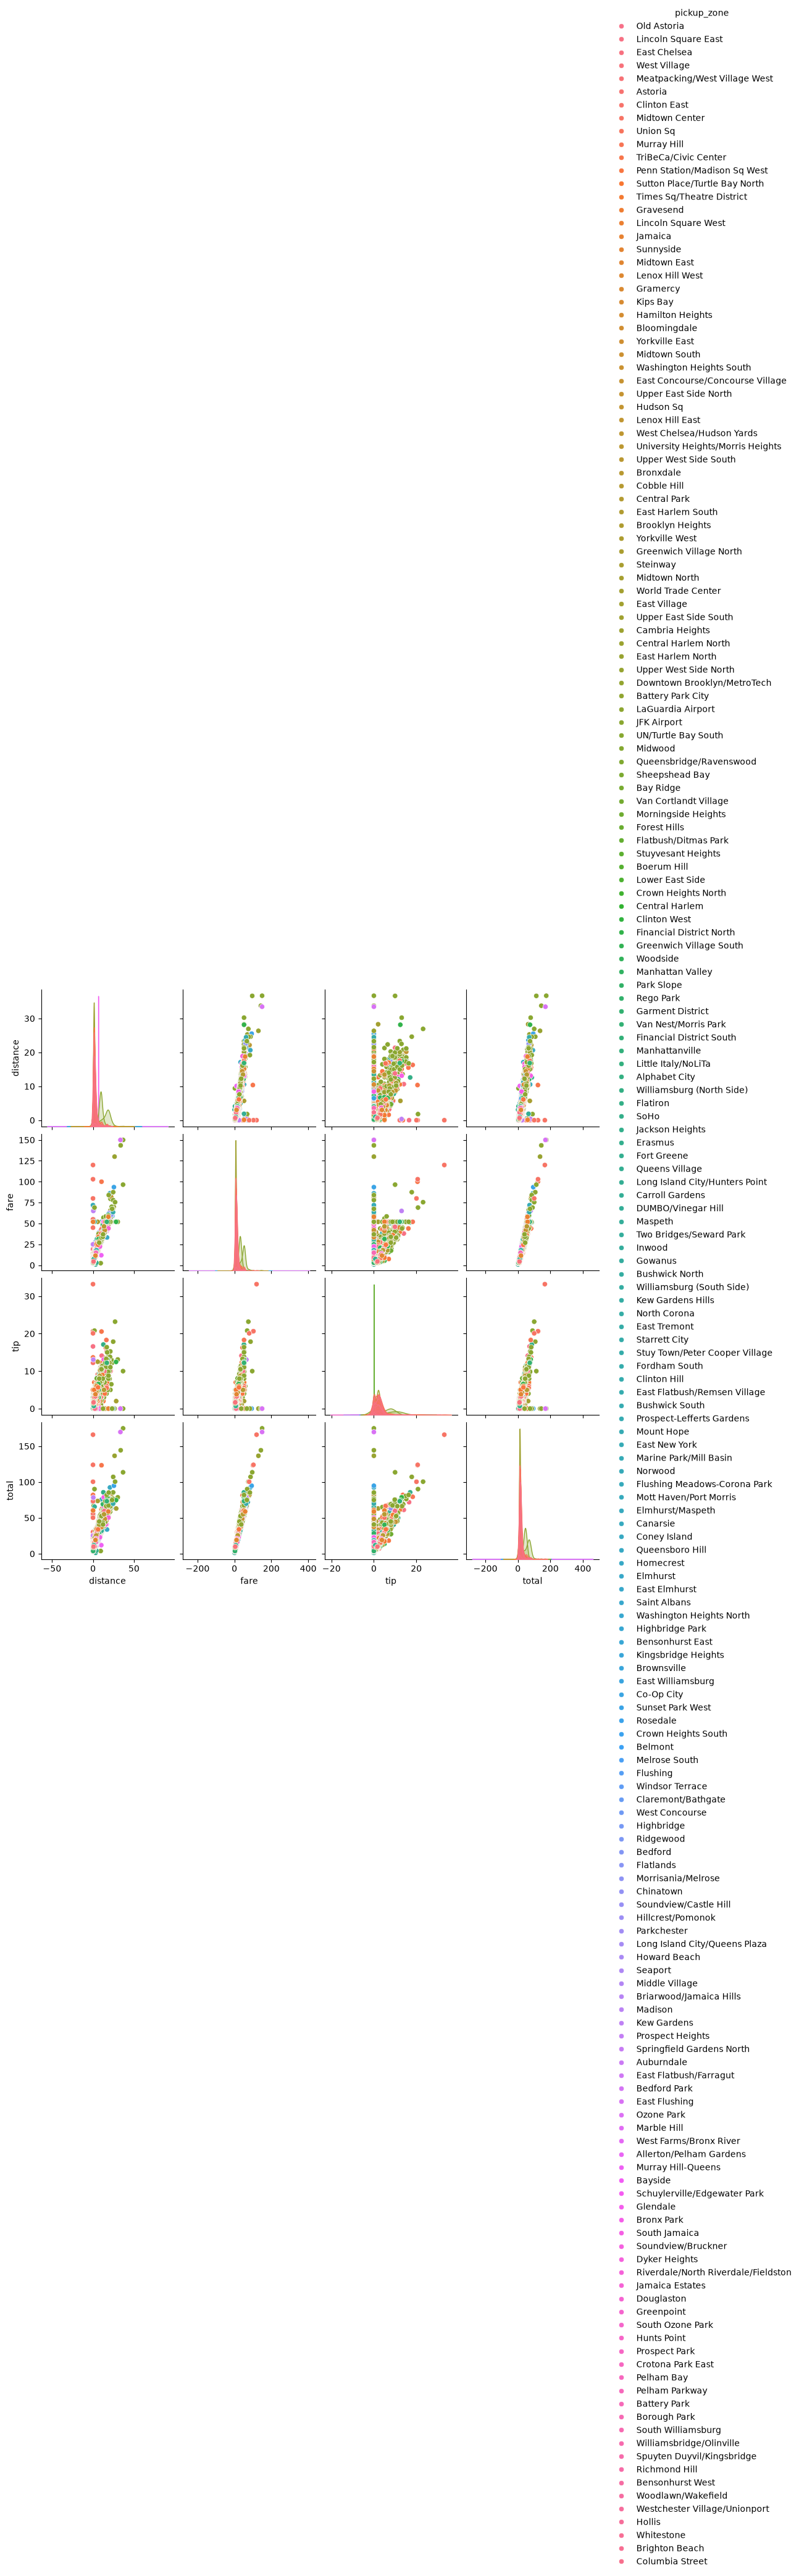

In [73]:
sns.pairplot(
    pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone"
)

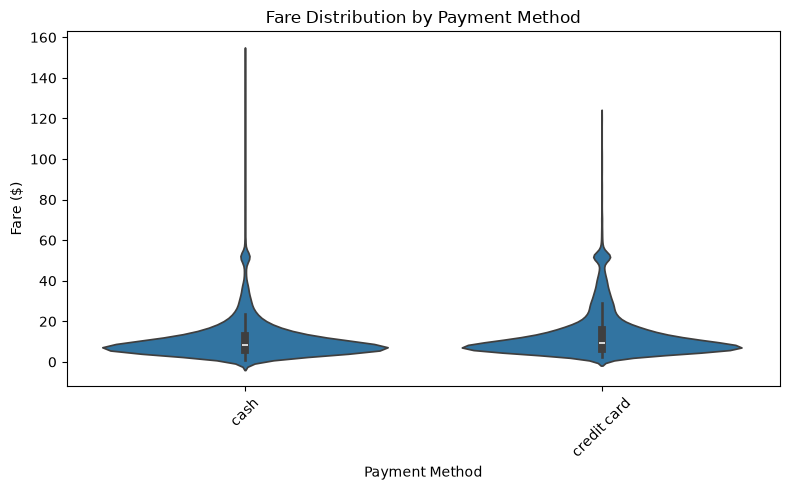

In [74]:

import seaborn as sns
import matplotlib.pyplot as plt

# Create violin plot
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

# Add title and labels
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")

# Display chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
